# Extension A: What goes wrong without randomisation

Throughout the main case the CFO's question, "would they have bought anyway?", was answered by **random assignment**. Most companies, most of the time, do not have that. They have data from a targeting system that decided who got a promotion, and they try to estimate the effect from it.

How badly can that go? Lazada (Alibaba Group) released the rare dataset that lets us check. The same voucher treatment appears twice:

| Data | How vouchers were assigned | Customers |
|---|---|---|
| **Targeted** (`train`) | By Lazada's targeting system | 926,669 |
| **Randomised** (`test`) | At random | 181,669 |

The randomised data gives the right answer. We will estimate the effect from the targeted data the way a company without an experiment would, and compare.

> The outcome is an anonymised `label` (most likely a purchase; Lazada does not define it) and the 83 features are anonymised. For this lesson that does not matter: the question is purely whether a method recovers the randomised answer. Run `make data-lazada` first.

In [1]:
import lightgbm as lgb
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from expt.causal import aipw_ate, cross_fit, ipw_ate, naive_difference, outcome_regression_ate, overlap_share
from expt.data import LAZADA_FEATURES, load_lazada
from expt.inference import compare_proportions
from expt.plotting import BAND, INK, INK_2, SERIES, new_figure, style_axes
from expt.validation import standardized_mean_difference

targeted = load_lazada("train")
randomised = load_lazada("test")
for name, d in [("Targeted", targeted), ("Randomised", randomised)]:
    print(f"{name:>10}: {len(d):,} customers, {d['is_treat'].mean():.0%} got a voucher")

  Targeted: 926,669 customers, 22% got a voucher
Randomised: 181,669 customers, 52% got a voucher


## 1. Two answers to the same question

In [2]:
def summary(d):
    t, c = d[d["is_treat"] == 1], d[d["is_treat"] == 0]
    return compare_proportions(t["label"].sum(), len(t), c["label"].sum(), len(c))

naive, rct = summary(targeted), summary(randomised)
pd.DataFrame({
    "Targeted data (naive comparison)": [naive.rate_treatment, naive.rate_control, naive.diff, naive.rate_treatment / naive.rate_control],
    "Randomised data": [rct.rate_treatment, rct.rate_control, rct.diff, rct.rate_treatment / rct.rate_control],
}, index=["outcome rate, voucher", "outcome rate, no voucher", "difference", "ratio"]).style.format("{:.4f}")

,Targeted data (naive comparison),Randomised data
"outcome rate, voucher",0.0566,0.0370
"outcome rate, no voucher",0.0094,0.0333
difference,0.0472,0.0037
ratio,5.9981,1.1124


In [3]:
print(f"Randomised effect: {rct.diff:+.2%} points (95% CI {rct.diff_low:+.2%} to {rct.diff_high:+.2%}), a {rct.lift:+.0%} lift")
print(f"Naive targeted estimate: {naive.diff:+.2%} points, {naive.diff / rct.diff:.0f}x the randomised effect")

Randomised effect: +0.37% points (95% CI +0.20% to +0.54%), a +11% lift
Naive targeted estimate: +4.72% points, 13x the randomised effect


The targeted data says vouchers multiply the outcome six-fold. The randomised data says they raise it by about 11%. A team reporting the naive number would overstate the voucher's effect about thirteen times, and spend accordingly.

## 2. Why: the targeted groups were never comparable

The same balance check as chapter 3, in both datasets:

In [4]:
def smd_all(d):
    t, c = d[d["is_treat"] == 1], d[d["is_treat"] == 0]
    return np.array([standardized_mean_difference(t[f], c[f]) for f in LAZADA_FEATURES])

smd_targeted, smd_randomised = np.abs(smd_all(targeted)), np.abs(smd_all(randomised))
for name, s in [("Targeted", smd_targeted), ("Randomised", smd_randomised)]:
    print(f"{name:>10}: median |SMD| {np.median(s):.3f}, largest {s.max():.2f}, features above 0.1: {(s > 0.1).sum()} of 83")

  Targeted: median |SMD| 0.407, largest 0.91, features above 0.1: 67 of 83
Randomised: median |SMD| 0.006, largest 0.05, features above 0.1: 0 of 83


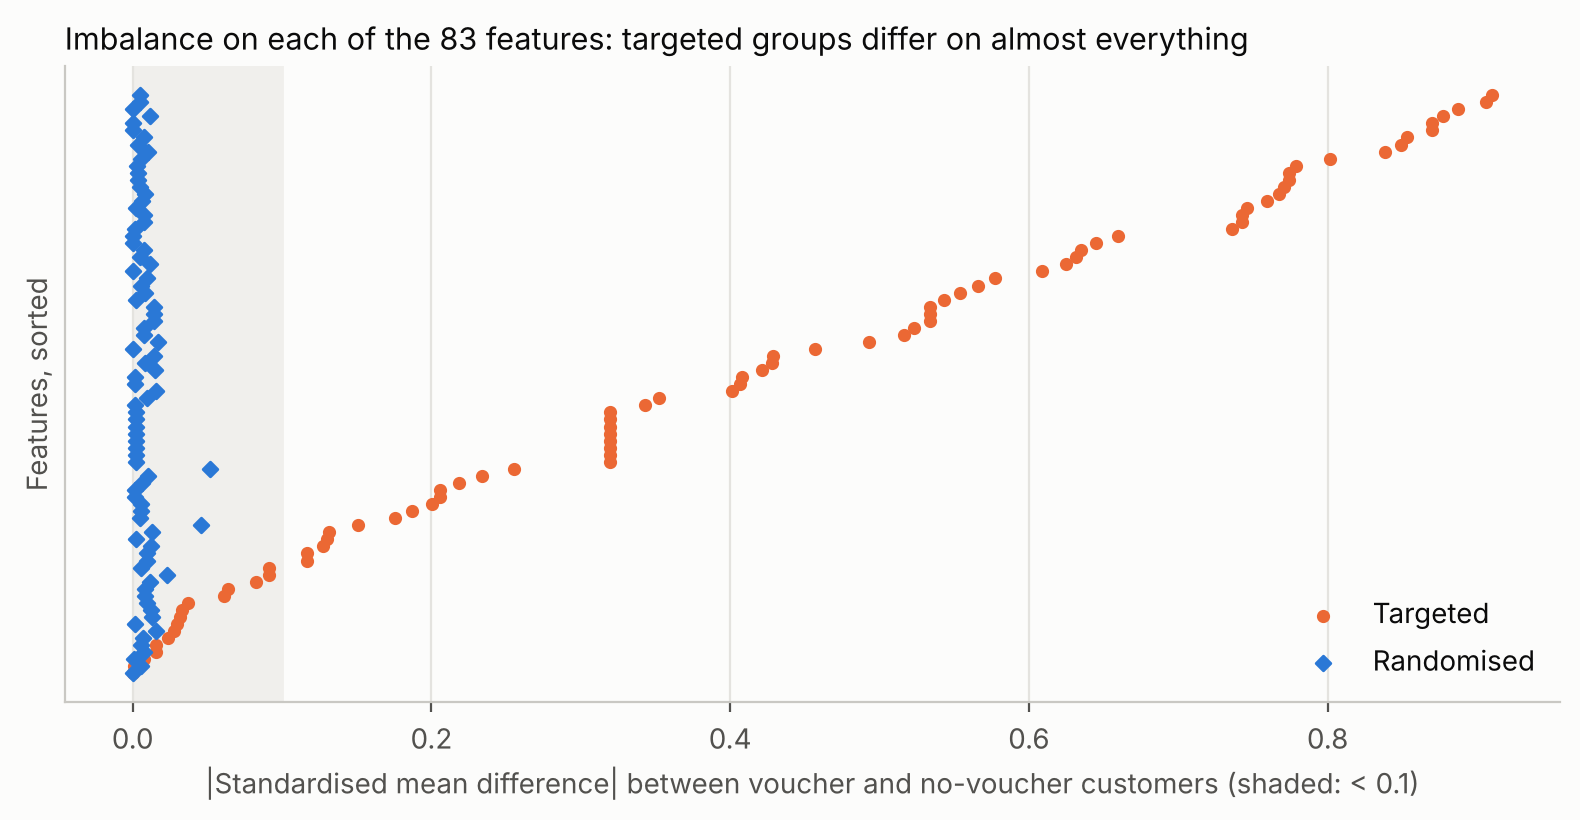

In [5]:
# figure: lazada_balance
fig, ax = new_figure(8, 4.2)
order = np.argsort(smd_targeted)
ax.axvspan(0, 0.1, color=BAND, zorder=0)
ax.scatter(smd_targeted[order], np.arange(83), s=14, color=SERIES[1], label="Targeted", zorder=3)
ax.scatter(smd_randomised[order], np.arange(83), s=14, color=SERIES[0], marker="D", label="Randomised", zorder=3)
ax.set_yticks([])
style_axes(ax, title="Imbalance on each of the 83 features: targeted groups differ on almost everything",
           xlabel="|Standardised mean difference| between voucher and no-voucher customers (shaded: < 0.1)",
           ylabel="Features, sorted", grid="x")
ax.legend(frameon=False, loc="lower right", labelcolor=INK)
plt.tight_layout()
plt.show()

The targeting system chose customers based on their characteristics, and those same characteristics drive the outcome. In the randomised data every feature is balanced.

## 3. Can statistics fix it?

Three standard corrections, each using the 83 features to adjust for how customers were chosen:

- **Outcome regression:** model the outcome with and without a voucher given the features, and average the predicted difference.
- **Inverse propensity weighting (IPW):** model each customer's probability of getting a voucher (the *propensity*), then weight customers so the two groups look alike.
- **Doubly robust (AIPW):** combine both; it is right if either model is right.

All three assume that the features capture *everything* that drove both targeting and the outcome. The models are gradient-boosted trees, cross-fitted so no customer is scored by a model trained on them. To keep the run time short we use a random 300,000 of the targeted customers.

In [6]:
sample = targeted.sample(300_000, random_state=1).reset_index(drop=True)
X = sample[LAZADA_FEATURES]
t = sample["is_treat"].to_numpy()
y = sample["label"].to_numpy().astype(float)

params = dict(n_estimators=200, learning_rate=0.05, num_leaves=31, min_child_samples=200, verbose=-1, n_jobs=2)
nuisance = cross_fit(X, t, y, lambda: lgb.LGBMClassifier(**params), lambda: lgb.LGBMClassifier(**params), n_folds=3)

First, look at the propensity scores: how predictable was the targeting?

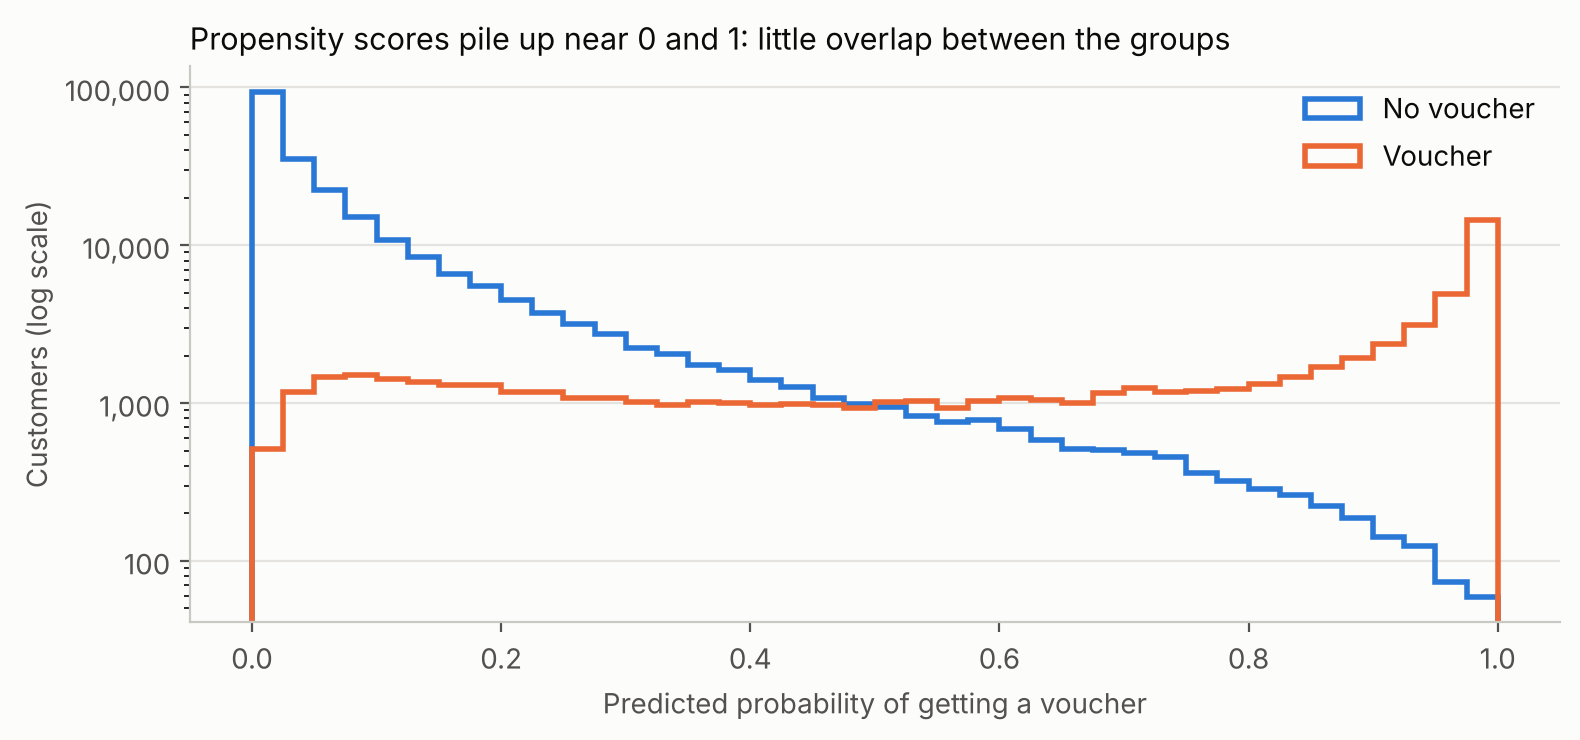

Customers with propensity below 5% or above 95%: 50%


In [7]:
# figure: lazada_overlap
fig, ax = new_figure(8, 3.8)
bins = np.linspace(0, 1, 41)
ax.hist(nuisance.propensity[t == 0], bins=bins, histtype="step", color=SERIES[0], linewidth=2, label="No voucher")
ax.hist(nuisance.propensity[t == 1], bins=bins, histtype="step", color=SERIES[1], linewidth=2, label="Voucher")
ax.set_yscale("log")
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:,.0f}"))
style_axes(ax, title="Propensity scores pile up near 0 and 1: little overlap between the groups",
           xlabel="Predicted probability of getting a voucher", ylabel="Customers (log scale)")
ax.legend(frameon=False, labelcolor=INK)
plt.tight_layout()
plt.show()
print(f"Customers with propensity below 5% or above 95%: {overlap_share(nuisance.propensity):.0%}")

Half of the customers were almost certain to get a voucher, or almost certain not to. For them, the other group contains hardly anyone similar to compare with. Every correction has to fill that gap by extrapolating from its model.

In [8]:
aipw = aipw_ate(y, t, nuisance)
estimates = pd.DataFrame({
    "estimate": [naive_difference(y, t), outcome_regression_ate(nuisance), ipw_ate(y, t, nuisance.propensity), aipw.estimate, rct.diff],
    "ci_low": [np.nan, np.nan, np.nan, aipw.ci_low, rct.diff_low],
    "ci_high": [np.nan, np.nan, np.nan, aipw.ci_high, rct.diff_high],
}, index=["Naive comparison", "Outcome regression", "IPW", "Doubly robust (AIPW)", "Randomised benchmark"])
estimates["x benchmark"] = estimates["estimate"] / rct.diff
estimates.style.format({"estimate": "{:+.2%}", "ci_low": "{:+.2%}", "ci_high": "{:+.2%}", "x benchmark": "{:.1f}x"}, na_rep="")

,estimate,ci_low,ci_high,x benchmark
Naive comparison,+4.67%,,,12.5x
Outcome regression,+0.92%,,,2.5x
IPW,+1.43%,,,3.8x
Doubly robust (AIPW),+0.77%,+0.58%,+0.97%,2.1x
Randomised benchmark,+0.37%,+0.20%,+0.54%,1.0x


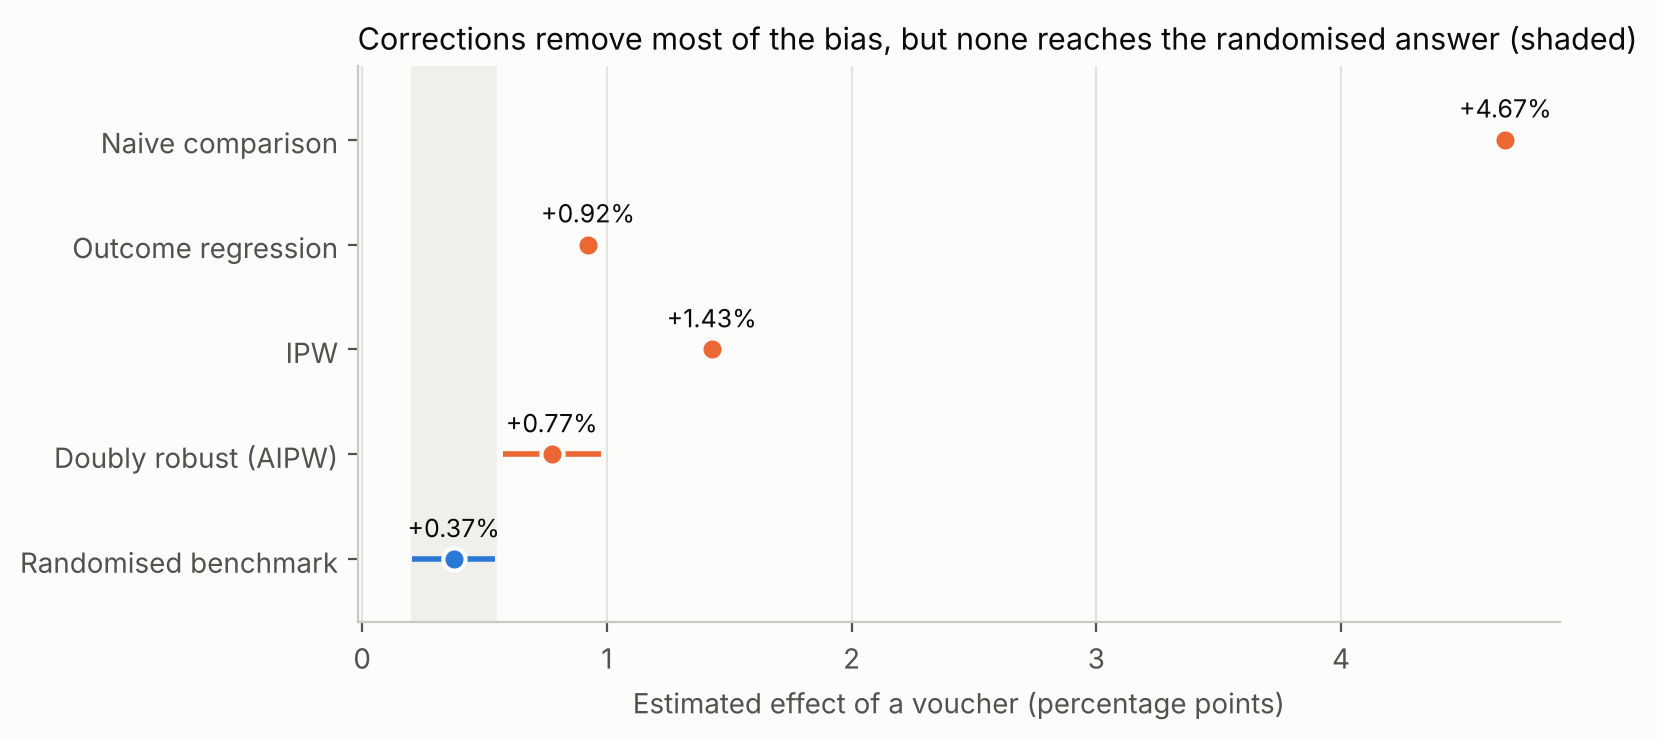

In [9]:
# figure: lazada_corrections
fig, ax = new_figure(8, 3.8)
names = list(estimates.index)[::-1]
ax.axvspan(rct.diff_low * 100, rct.diff_high * 100, color=BAND, zorder=0)
for i, name in enumerate(names):
    r = estimates.loc[name]
    color = SERIES[0] if name == "Randomised benchmark" else SERIES[1]
    if not np.isnan(r["ci_low"]):
        ax.hlines(i, r["ci_low"] * 100, r["ci_high"] * 100, color=color, linewidth=2)
    ax.plot(r["estimate"] * 100, i, "o", color=color, markersize=8, markeredgecolor="#fcfcfb", markeredgewidth=1.5)
    ax.annotate(f"{r['estimate']:+.2%}", (r["estimate"] * 100, i), xytext=(0, 8), textcoords="offset points",
                ha="center", color=INK, fontsize=9)
ax.set_yticks(range(len(names)), names)
ax.set_ylim(-0.6, len(names) - 0.3)
style_axes(ax, title="Corrections remove most of the bias, but none reaches the randomised answer (shaded)",
           xlabel="Estimated effect of a voucher (percentage points)", grid="x")
plt.tight_layout()
plt.show()

The corrections do a lot: they bring the estimate from about 13 times the truth down to roughly 2–4 times. But none recovers the randomised answer, and the doubly robust confidence interval, which *looks* precise, does not even contain it. That false precision is the most dangerous part: an analyst would present a tight interval around the wrong number.

## 4. Why the corrections fall short

**1. No overlap.** For half the customers there is no comparable customer in the other group, so the answer for them comes from model extrapolation, not data.

**2. Unmeasured reasons for targeting.** The corrections assume the features capture everything that drove both the targeting and the outcome. If the targeting system used anything else (recent browsing, stock levels, campaign calendars), the bias remains, and nothing in the data reveals it.

**3. Different populations.** The two files do not describe the same customers:

In [10]:
shift = np.abs([standardized_mean_difference(randomised[f], targeted[f]) for f in LAZADA_FEATURES])
print(f"Features that differ between the targeted and randomised files (|SMD| > 0.1): {(shift > 0.1).sum()} of 83")
print(f"Outcome rate without a voucher: targeted {naive.rate_control:.2%}, randomised {rct.rate_control:.2%}")

Features that differ between the targeted and randomised files (|SMD| > 0.1): 55 of 83
Outcome rate without a voucher: targeted 0.94%, randomised 3.33%


The randomised experiment was run on a different set of customers, probably at a different time. So even a perfect correction would estimate the effect for a *different* population. One more check: apply the outcome models trained on the targeted data to the randomised customers and predict the effect there.

In [11]:
models = {}
for arm in [0, 1]:
    models[arm] = lgb.LGBMClassifier(**params).fit(X[t == arm], y[t == arm])
predicted = (models[1].predict_proba(randomised[LAZADA_FEATURES])[:, 1]
             - models[0].predict_proba(randomised[LAZADA_FEATURES])[:, 1]).mean()
print(f"Effect predicted for the randomised customers by models trained on targeted data: {predicted:+.2%}")
print(f"Effect actually measured on them by the experiment:                            {rct.diff:+.2%}")

Effect predicted for the randomised customers by models trained on targeted data: +1.21%
Effect actually measured on them by the experiment:                            +0.37%


Even on the customers the experiment measured, models learned from targeted data predict an effect several times too large.

## 5. Lessons

1. **Targeted data can overstate an effect by an order of magnitude.** The people a system chooses are chosen *because* they are likely to respond, or to buy anyway.
2. **Statistical corrections help but are not a substitute for randomisation** when targeting is strong. They rely on overlap and on measuring every reason for targeting, and neither can be verified from the data alone.
3. **Their confidence intervals measure sampling noise, not bias.** A narrow interval around a biased estimate is worse than no estimate.
4. **Validate against an experiment whenever you can.** This is why the main case's holdout group, and the long-term holdout recommended in the [decision memo](../docs/company_documents/ch6_decision_memo.md), are worth their cost: they are the only way to know.

## Try it yourself

**a)** Change the propensity clipping in `ipw_ate` from 0.01 to 0.05 and 0.10. How much does the IPW estimate move? What does that tell you?

**b)** Rerun section 3 with a different random sample (`random_state=2`). How stable are the corrected estimates?

**c)** A product manager says "our observational model says vouchers lift purchases 2.5x; we don't need an experiment". Using this lesson, write a three-sentence reply.